--- Augmented Dickey-Fuller Test ---
ADF Statistic: -6.9427
p-value: 0.0000
Result: Data is stationary (Reject the null hypothesis)
                               SARIMAX Results                                
Dep. Variable:           order_volume   No. Observations:                  292
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -942.591
Date:                Thu, 29 Oct 2026   AIC                           1891.181
Time:                        17:37:47   BIC                           1902.201
Sample:                    10-23-2025   HQIC                          1895.596
                         - 08-10-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0343      0.057     -0.601      0.548      -0.146       0.077

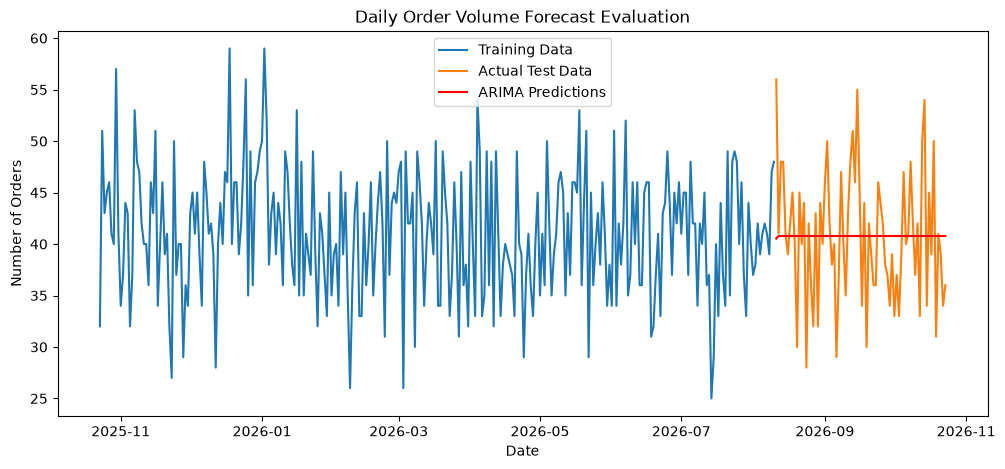

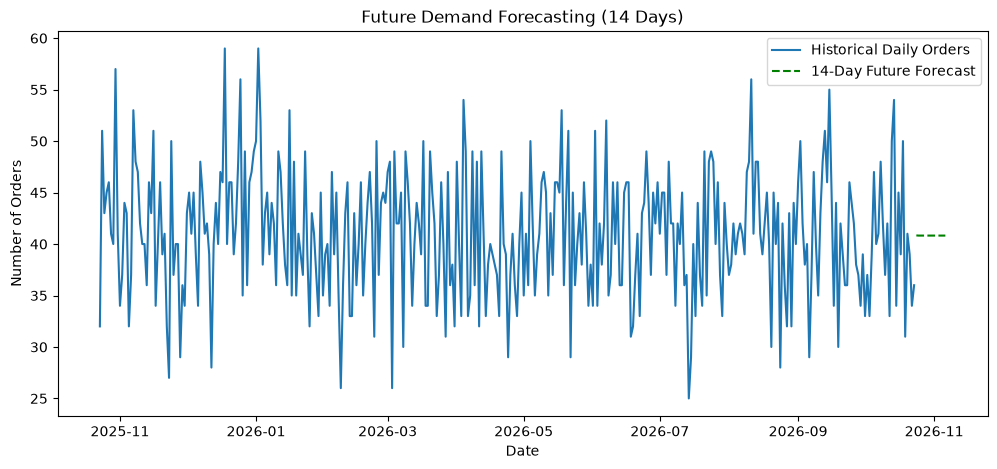

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# Part 1: Temporal Data Aggregation
orders = pd.read_csv('../data/orders.csv')

# Convert timestamp to datetime and set as index
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])
orders.set_index('order_timestamp', inplace=True)

# Aggregate data to daily frequency (Order Volume)
# Note: To forecast revenue instead, use: daily_data = orders['order_amount'].resample('D').sum()
daily_data = orders.resample('D').size().rename('order_volume')

# Fill any missing dates with 0 (if the restaurant was closed or had no orders)
daily_data = daily_data.fillna(0)

# Part 2: Stationarity Testing (Augmented Dickey-Fuller Test)
def test_stationarity(timeseries):
    print("--- Augmented Dickey-Fuller Test ---")
    adf_test = adfuller(timeseries, autolag='AIC')
    print(f"ADF Statistic: {adf_test[0]:.4f}")
    print(f"p-value: {adf_test[1]:.4f}")
    if adf_test[1] <= 0.05:
        print("Result: Data is stationary (Reject the null hypothesis)")
    else:
        print("Result: Data is non-stationary (Fail to reject the null hypothesis)")
        
test_stationarity(daily_data)

# Part 3: ARIMA Modeling (Train/Test Split & Training)
# Split sequentially (80% train, 20% test)
train_size = int(len(daily_data) * 0.8)
train_data, test_data = daily_data.iloc[:train_size], daily_data.iloc[train_size:]

# Initialize and fit ARIMA model
# order=(p,d,q): Using (1,1,1) as a standard baseline for non-stationary data
arima_model = ARIMA(train_data, order=(1, 1, 1))
fitted_arima = arima_model.fit()
print(fitted_arima.summary())

# Part 4: Forecast Evaluation
# Generate predictions for the test set
predictions = fitted_arima.forecast(steps=len(test_data))
predictions.index = test_data.index

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(test_data, predictions))
print(f"\n--- Model Evaluation ---")
print(f"Test RMSE: {rmse:.2f}")

# Plot Train, Test, and Predictions
plt.figure(figsize=(12, 5))
plt.plot(train_data.index, train_data, label='Training Data')
plt.plot(test_data.index, test_data, label='Actual Test Data')
plt.plot(predictions.index, predictions, color='red', label='ARIMA Predictions')
plt.title('Daily Order Volume Forecast Evaluation')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.legend()
plt.show()

# Part 5: Future Forecasting (Next 14 Days)
# Train on the ENTIRE dataset for future predictions
final_model = ARIMA(daily_data, order=(1, 1, 1))
final_fitted = final_model.fit()

# Forecast next 14 days
future_steps = 14
future_forecast = final_fitted.forecast(steps=future_steps)
future_dates = pd.date_range(start=daily_data.index[-1] + pd.Timedelta(days=1), periods=future_steps)
future_forecast.index = future_dates

# Plot Historical Data + Future Forecast
plt.figure(figsize=(12, 5))
plt.plot(daily_data.index, daily_data, label='Historical Daily Orders')
plt.plot(future_forecast.index, future_forecast, color='green', linestyle='--', label='14-Day Future Forecast')
plt.title('Future Demand Forecasting (14 Days)')
plt.xlabel('Date')
plt.ylabel('Number of Orders')
plt.legend()
plt.show()